# Quantum-Assisted Multi-Agent System Optimization for Autonomous Swarms

**Classical A\*, Prioritized Planning, with a Quantum-Inspired (QUBO) Extension**

**Dataset:** Moving AI Lab MAPF benchmark – https://movingai.com/benchmarks/mapf.html

**Objective:** coordinate several drones in a shared grid so that every drone reaches its goal, without hitting obstacles or other drones, with a short total distance and a short mission time.


# 1. Understanding the Problem

**Multi-Agent Path Finding (MAPF)**: several agents must travel from their own start to their own goal in the same environment without colliding.

Consider a group of autonomous drones (agents) operating in a shared environment. Each drone has a starting location and a designated target location.
The objective is to coordinate the movement of multiple drones to reach their respective destinations while avoiding obstacles and collisions and minimizing overall travel distance and mission completion time.

**Challenges:** colliding shortest paths, congestion in narrow gaps, and scalability (the number of joint plans grows exponentially with the number of drones).

# 2. Importing Libraries

In [17]:
import os, glob, math, time, heapq, zipfile, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SQRT2 = math.sqrt(2)
COLORS = plt.cm.tab10.colors

# 3. Dataset Loading

The Moving AI benchmark `random-32-32-10` is a 32 × 32 grid with about 10 % random obstacles.

**Even vs. random files:** *even* files spread the problems evenly over short, medium and long trips. *Random* files pick start and goal at random. This project uses the **even** files.

**Window:** to keep the problem small, I use the top-left **20 × 20 window** of the map. Only scenario entries with start and goal inside this window (on free cells) are used.

The cell below finds the files in the `Data` folder (or extracts the ZIP files), reads the map and reads the 25 even scenario files.

In [18]:
MAP_NAME = "random-32-32-10"

def find_files(ext):

    hits = []
    for folder in ["Data", "../Data", "data", "../data", "."]:
        hits += glob.glob(os.path.join(folder, "**", "*" + ext), recursive=True)
    return {os.path.basename(h): os.path.abspath(h) for h in sorted(hits)}

def have_data():

    maps, scens = find_files(".map"), find_files(".scen")
    return (MAP_NAME + ".map") in maps and any(n.startswith(MAP_NAME + "-even-") for n in scens)

if not have_data():
    os.makedirs("mapf_data", exist_ok=True)
    for z in find_files(".zip").values():
        zipfile.ZipFile(z).extractall("mapf_data")

map_files, scen_files = find_files(".map"), find_files(".scen")

def natural(name):
    return int(name.rsplit("-", 1)[1].split(".")[0])

def load_map(path):
    rows = [r.strip() for r in open(path).read().splitlines()]
    rows = [r for r in rows[rows.index("map") + 1:] if r]
    return np.array([[0 if ch in ".GS" else 1 for ch in r] for r in rows])
def load_scen(path):

    cols = ["bucket", "map", "width", "height", "sx", "sy", "gx", "gy", "optimal"]
    return pd.read_csv(path, sep="\t", skiprows=1, header=None, names=cols)

full_map = load_map(map_files[MAP_NAME + ".map"])
N = 20
grid_array = full_map[:N, :N]
def inside_window(df):

    keep = [max(r.sx, r.sy, r.gx, r.gy) < N and grid_array[r.sy, r.sx] == 0 and grid_array[r.gy, r.gx] == 0
            and (r.sx, r.sy) != (r.gx, r.gy) for r in df.itertuples()]
    return df[keep].reset_index(drop=True)

even_scens = {n: inside_window(load_scen(p)) for n, p in sorted(scen_files.items(), key=lambda kv: natural(kv[0])) if n.startswith(MAP_NAME + "-even-")}
print("Using map file:", map_files[MAP_NAME + ".map"])
print(f"Benchmark map {full_map.shape[1]} x {full_map.shape[0]} -> window {N} x {N} | even scenario files: {len(even_scens)} "
      f"(entries inside the window per file: {min(map(len, even_scens.values()))} to {max(map(len, even_scens.values()))})")

Using map file: C:\Users\DELL\Downloads\random-32-32-10.map\random-32-32-10.map
Benchmark map 32 x 32 -> window 20 x 20 | even scenario files: 25 (entries inside the window per file: 6 to 17)


**Observations:**
- The map file and 25 even scenario files were found and read.
- The 32 × 32 map is reduced to a 20 × 20 window.
- Only 6 to 17 entries per scenario file lie completely inside the window, so each file offers enough start/goal pairs to build a group of 5 drones.

# 4. Exploratory Data Analysis (EDA)

## 4.1 Environment and Scenario Summary

,value
Grid size (columns x rows),20 x 20
Total cells,400
Free cells,351
Obstacle cells,49
Obstacle density (%),12.3
Scenario entries inside the window (25 files),324
Start-goal distance - mean,8.1
Start-goal distance - min / max,1.0 / 23.1


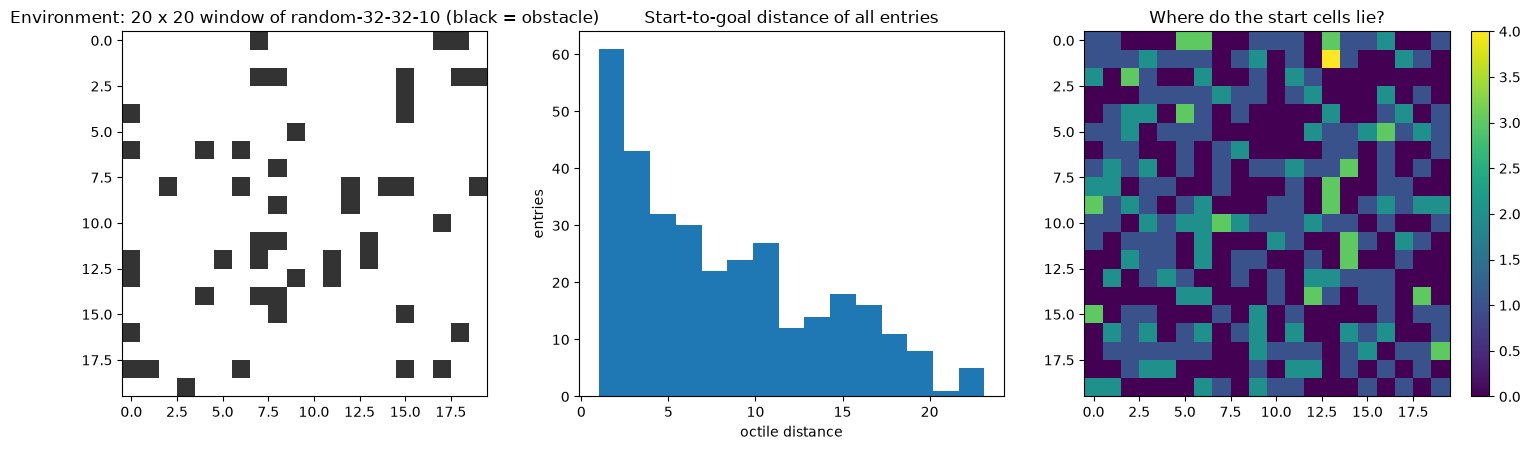

In [19]:
all_even = pd.concat(even_scens.values())
dx, dy = (all_even.gx - all_even.sx).abs(), (all_even.gy - all_even.sy).abs()
all_even["straight"] = np.maximum(dx, dy) + (SQRT2 - 1) * np.minimum(dx, dy)
free = int((grid_array == 0).sum())
env_stats = pd.Series({
    "Grid size (columns x rows)": f"{N} x {N}", "Total cells": grid_array.size, "Free cells": free,
    "Obstacle cells": grid_array.size - free, "Obstacle density (%)": round(100 * (1 - free / grid_array.size), 1),
    "Scenario entries inside the window (25 files)": len(all_even),
    "Start-goal distance - mean": round(all_even.straight.mean(), 1),
    "Start-goal distance - min / max": f"{all_even.straight.min():.1f} / {all_even.straight.max():.1f}"}, name="value")
display(env_stats.to_frame())

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].imshow(grid_array, cmap=ListedColormap(["white", "#333333"]))
ax[0].set_title(f"Environment: {N} x {N} window of {MAP_NAME} (black = obstacle)")
ax[1].hist(all_even.straight, bins=15, color="tab:blue")
ax[1].set(title="Start-to-goal distance of all entries", xlabel="octile distance", ylabel="entries")
dens = np.histogram2d(all_even.sy, all_even.sx, bins=[range(N + 1), range(N + 1)])[0]
im = ax[2].imshow(dens, cmap="viridis"); ax[2].set_title("Where do the start cells lie?"); plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()

**Observations:**
- The window has 400 cells: 351 free and 49 obstacles (12.3 %).
- The 324 usable entries have a mean start-to-goal distance of 8.1 (minimum 1.0, maximum 23.1).
- **Environment plot:** obstacles are small, scattered single cells and short horizontal or vertical pairs. Large free areas remain, but there are many narrow diagonal gaps.
- **Distance histogram:** the distribution is right-skewed. Most trips are short (under 10 cells), and only a few reach 20 or more.
- **Start-cell heat map:** start cells are spread over the whole window with no hot spot. A cell is a start at most 4 times in the 324 entries.
- Because many trips are short compared with the 20-cell width, drones often do not meet at all. A fixed rule is therefore used in Section 6.1 to pick a file in which drones really meet.

# 5. Object-Oriented Solution
| Class | Purpose |
|---|---|
| `Grid` | the map: free/blocked cells, the 8 allowed moves and their costs |
| `Drone` | one drone: start, goal, path, distance, arrival time |
| `Planner` | **A\***; with reservations it searches over (cell, time) and can wait |
| `Reservations` | memory of the cells and moves already taken at each time step |
| `Coordinator` | plans all drones independently, or with **prioritized planning** |

**A\*:** always expands the cell with the lowest `cost so far + estimated cost left`. The estimate (octile distance) never over-estimates, so the path is the shortest.

**Prioritized planning:**
1. Drones with the longest trip plan first.
2. Each drone reserves the cells it uses at each time step.
3. The next drone plans around the reservations: it detours or **waits**.
4. A drone that arrived stays parked at its goal, so that cell stays reserved.

## 5.1 Environment, Drone, Reservations and Planner

In [20]:
class Grid:
    # The environment. Cell = (x, y); array value 0 = free, 1 = obstacle.
    MOVES = [(1, 0), (-1, 0), (0, 1), (0, -1), (1, 1), (1, -1), (-1, 1), (-1, -1)]

    def __init__(self, array):
        self.grid = np.array(array)
        self.h, self.w = self.grid.shape

    def free(self, c):
        # True if the cell is inside the grid AND is not an obstacle
        return 0 <= c[0] < self.w and 0 <= c[1] < self.h and self.grid[c[1], c[0]] == 0
    def neighbors(self, c):
        # Yields (next_cell, cost). A diagonal move needs both side cells free (no corner cutting).
        for dx, dy in self.MOVES:
            n = (c[0] + dx, c[1] + dy)
            if not self.free(n):
                continue
            if dx and dy and not (self.free((c[0] + dx, c[1])) and self.free((c[0], c[1] + dy))):
                continue
            yield n, (SQRT2 if dx and dy else 1.0)
    @staticmethod
    def step_cost(a, b):
        return 0.0 if a == b else (SQRT2 if a[0] != b[0] and a[1] != b[1] else 1.0)
    @staticmethod
    def octile(a, b):
        dx, dy = abs(a[0] - b[0]), abs(a[1] - b[1])
        return max(dx, dy) + (SQRT2 - 1) * min(dx, dy)
class Drone:
    # One autonomous agent.
    def __init__(self, id, start, goal):
        self.id, self.start, self.goal, self.path = id, start, goal, None
    @property
    def distance(self):
        return sum(Grid.step_cost(a, b) for a, b in zip(self.path, self.path[1:])) if self.path else 0.0
    @property
    def arrival_time(self):
        return len(self.path) - 1 if self.path else None
    @property
    def reached(self):
        return bool(self.path) and self.path[-1] == self.goal

    def at(self, t):
        return self.path[min(t, len(self.path) - 1)] if self.path else self.start
class Reservations:
    # Coordinator memory: which cells and moves are already taken at which time.
    def __init__(self):
        self.cells, self.moves, self.last, self.parked = set(), set(), {}, {}

    def add(self, path):
        # Save a planned path so that the next drones can avoid it
        for t, c in enumerate(path):
            self.cells.add((c, t))
            self.last[c] = max(self.last.get(c, 0), t)
            if t and path[t - 1] != c:
                self.moves.add((path[t - 1], c, t - 1))
        self.parked[path[-1]] = len(path) - 1

    def blocked(self, a, b, t):
        # Why may a drone NOT go from a (time t) to b (time t+1)? Returns the conflict type or None.
        if (b, t + 1) in self.cells or self.parked.get(b, math.inf) <= t + 1:
            return "vertex"
        if a != b:
            if (b, a, t) in self.moves:
                return "swap"
            if a[0] != b[0] and a[1] != b[1]:
                p, q = (a[0], b[1]), (b[0], a[1])
                if (p, q, t) in self.moves or (q, p, t) in self.moves:
                    return "crossing"
        return None
class Planner:
    # A* on the 8-direction grid. With reservations the search state is (cell, time) and waiting is allowed.
    def __init__(self, env, max_time=100, wait_cost=0.01):
        self.env, self.max_time, self.wait_cost = env, max_time, wait_cost

    def plan(self, start, goal, res=None):
        env, tick = self.env, 0
        t_goal = (res.last.get(goal, -1) + 1) if res else 0
        heap = [(env.octile(start, goal), 0, 0.0, start, 0)]
        best, parent = {(start, 0): 0.0}, {(start, 0): None}
        while heap:
            f, _, g, c, t = heapq.heappop(heap)
            if g > best[(c, t)] + 1e-12:
                continue
            if c == goal and t >= t_goal:
                path, s = [], (c, t)
                while s:
                    path.append(s[0]); s = parent[s]
                return path[::-1]
            if res and t >= self.max_time:
                continue
            moves = list(env.neighbors(c)) + ([(c, self.wait_cost)] if res else [])
            for n, cost in moves:
                if res and res.blocked(c, n, t):
                    continue
                key, ng = (n, t + 1 if res else 0), g + cost
                if ng < best.get(key, math.inf) - 1e-12:
                    best[key], parent[key] = ng, (c, t)
                    tick += 1
                    heapq.heappush(heap, (ng + env.octile(n, goal), tick, ng, n, key[1]))
        return None

**Observation:** `Grid` forbids corner cutting for diagonal moves. `Planner.plan(start, goal)` is plain A\*; `Planner.plan(start, goal, reservations)` is space-time A\*, where waiting is allowed and conflicting moves are skipped.

## 5.2 Conflict Detection, Coordinator and Metrics

In [21]:
def find_conflicts(paths):
    # Counting vertex, swap and diagonal-crossing conflicts in {drone_id: path} (drones park at their goal).
    ids, T = list(paths), max(len(p) for p in paths.values())
    at = lambda i, t: paths[i][min(t, len(paths[i]) - 1)]
    out = {"vertex": 0, "swap": 0, "crossing": 0}
    for t in range(T):
        for k, i in enumerate(ids):
            for j in ids[k + 1:]:
                a, b, c, d = at(i, t), at(i, t + 1), at(j, t), at(j, t + 1)
                if a == c:
                    out["vertex"] += 1
                if a != b and a == d and b == c:
                    out["swap"] += 1
                if a[0] != b[0] and a[1] != b[1] and c[0] != d[0] and c[1] != d[1] \
                        and {c, d} == {(a[0], b[1]), (b[0], a[1])}:
                    out["crossing"] += 1
    return out

class Coordinator:
    # Plans all drones: independently (baseline) or with prioritized planning (coordination).
    def __init__(self, env):
        self.env, self.planner = env, Planner(env)

    def plan_independent(self, drones):
        for d in drones:
            d.path = self.planner.plan(d.start, d.goal)

    def plan_prioritized(self, drones):
        for d in drones:
            p = self.planner.plan(d.start, d.goal)
            d.solo = sum(Grid.step_cost(a, b) for a, b in zip(p, p[1:])) if p else 0.0
        res = Reservations()
        for d in sorted(drones, key=lambda d: (-d.solo, d.id)):
            d.path = self.planner.plan(d.start, d.goal, res)
            res.add(d.path if d.path else [d.start])

def evaluate(drones, seconds):
    # The five performance metrics.
    c = find_conflicts({d.id: d.path or [d.start] for d in drones})
    ok = [d for d in drones if d.reached]
    return {"Total travel distance": round(sum(d.distance for d in drones), 2),
            "Conflicts (total)": sum(c.values()), "   vertex": c["vertex"], "   swap": c["swap"], "   crossing": c["crossing"],
            "Agents reaching goal (%)": 100 * len(ok) / len(drones),
            "Completion time (steps)": max([d.arrival_time for d in ok], default=0),
            "Execution time (ms)": round(1000 * seconds, 1)}

env = Grid(grid_array)
def make_drones(entries):
    # Turn the rows of a scenario table into Drone objects
    return [Drone(i, (r.sx, r.sy), (r.gx, r.gy)) for i, r in enumerate(entries.itertuples())]
def run_method(entries, method):
    # Plan with the chosen method, measure the time and return (drones, metrics)
    drones, t0 = make_drones(entries), time.perf_counter()
    getattr(Coordinator(env), method)(drones)
    return drones, evaluate(drones, time.perf_counter() - t0)

**Observations:**
- `find_conflicts` counts vertex, swap and crossing conflicts at every time step.
- `plan_independent` is the baseline (every drone uses its own A\* path); `plan_prioritized` is the coordination method.
- `evaluate` returns the five required metrics: total travel distance, conflicts, % of drones reaching their goal, completion time and execution time.

# 6. Experiments

## 6.1 Choosing the Scenario Instance
The first valid pairs of a scenario file are used as drones. Scenario 1 uses the first 2 drones and Scenario 2 uses all 5, so both are comparable.

Random paths often never meet, and then there is nothing to coordinate. So a **fixed rule** picks the file: *the first even file, in numeric order, in which the first 2 drones collide when they use independent A\**. The result is the same on every run.

In [22]:
def pick_agents(df, n):
    # First n entries (file order) with distinct starts, distinct goals and a reachable goal.
    chosen, starts, goals = [], set(), set()
    for r in df.itertuples():
        s, g = (r.sx, r.sy), (r.gx, r.gy)
        if s != g and s not in starts and g not in goals and Planner(env).plan(s, g) is not None:
            chosen.append(r); starts.add(s); goals.add(g)
        if len(chosen) == n:
            break
    assert chosen, (f"pick_agents found no valid entries: this file has {len(df)} entries, grid is {env.w} x {env.h}. "
                    "Run the data cell and the Grid/Planner cell first (Restart & Run All).")
    return pd.DataFrame([r._asdict() for r in chosen]).drop(columns="Index", errors="ignore").reset_index(drop=True)

SCEN_FILE = next(name for name, df in even_scens.items()
                 if run_method(pick_agents(df, 2), "plan_independent")[1]["Conflicts (total)"] > 0)
agents5 = pick_agents(even_scens[SCEN_FILE], 5)
agents = {2: agents5.iloc[:2], 5: agents5}
print("Selected scenario file:", SCEN_FILE)
display(agents5[["sx", "sy", "gx", "gy"]].rename_axis("drone"))

Selected scenario file: random-32-32-10-even-2.scen


,sx,sy,gx,gy
drone,,,,
0,2,6,11,16
1,6,9,5,9
2,12,13,13,9
3,11,18,13,7
4,13,0,14,2


**Observations:**
- The rule selects `random-32-32-10-even-2.scen`; the first file has no collision among its first 2 drones.
- The trips differ a lot in length: drone 0 has a long diagonal trip across the map, while drone 1 (one cell) and drone 4 (two cells) have very short trips.
- Drones 1 and 4 have their start and goal very close together, so they hardly interact with the other drones.


For each drone the real A\* distance is compared with the straight-line (octile) distance. The ratio shows the detour caused by obstacles. Then every pair of drones is checked for **shared cells** (potential conflicts) and for **real conflicts** (same cell at the same time).

In [23]:
drones5, _ = run_method(agents5, "plan_independent")
rows = [{"drone": d.id, "start": d.start, "goal": d.goal,
         "A* distance": round(d.distance, 2), "straight-line": round(env.octile(d.start, d.goal), 2),
         "detour ratio": round(d.distance / env.octile(d.start, d.goal), 2), "steps": d.arrival_time} for d in drones5]
display(pd.DataFrame(rows).set_index("drone"))

pairs = []
for a, b in itertools.combinations(drones5, 2):
    shared = set(a.path) & set(b.path)
    real = sum(find_conflicts({0: a.path, 1: b.path}).values())
    pairs.append({"pair": f"{a.id}-{b.id}", "shared cells": len(shared), "real conflicts": real})
pairs = pd.DataFrame(pairs).set_index("pair")
print(f"Pairs whose paths overlap in space: {(pairs['shared cells'] > 0).sum()} of {len(pairs)}  |  pairs that really collide: {(pairs['real conflicts'] > 0).sum()}")
display(pairs[pairs["shared cells"] > 0])

,start,goal,A* distance,straight-line,detour ratio,steps
drone,,,,,,
0,"(2, 6)","(11, 16)",15.49,13.73,1.13,13
1,"(6, 9)","(5, 9)",1.00,1.00,1.00,1
2,"(12, 13)","(13, 9)",5.00,4.41,1.13,5
3,"(11, 18)","(13, 7)",12.41,11.83,1.05,12
4,"(13, 0)","(14, 2)",2.41,2.41,1.00,2


Pairs whose paths overlap in space: 3 of 10  |  pairs that really collide: 2


,shared cells,real conflicts
pair,,
0-1,1,1
0-3,1,0
2-3,6,1


**Observations:**
- Detour ratios are between 1.00 and 1.13, so obstacles add at most 13 % to a path. The longest drone (drone 0) needs 15.49 against 13.73 in a straight line.
- 3 of the 10 drone pairs share cells, and 2 of them really collide.
- Pair 0-3 shares one cell but does **not** collide, because the two drones are in that cell at different times. This shows the difference between a *potential* and a *real* conflict.
- Pair 2-3 shares 6 cells because both drones use the same narrow corridor, and it produces a real conflict.

## 6.3 Start, Goal and Independent Paths

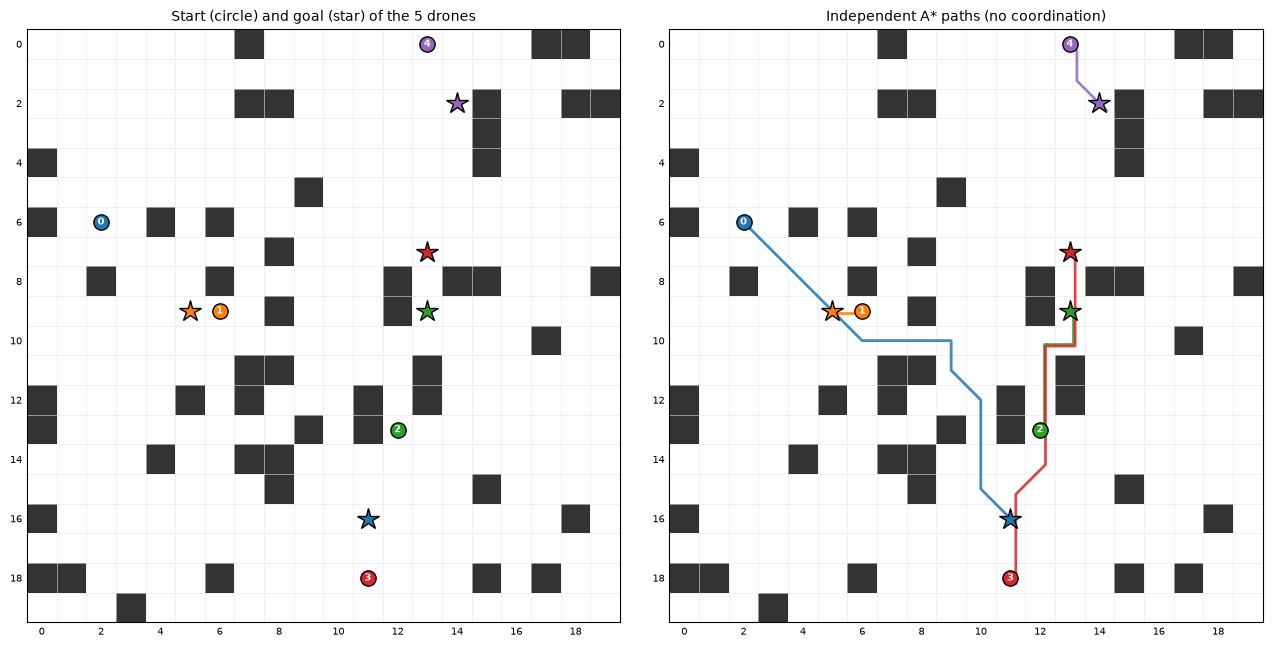

In [24]:
def draw_map(ax, title=""):
    # Draw the 20x20 map on the given plot area (ax)
    ax.imshow(env.grid, cmap=ListedColormap(["white", "#333333"]))
    ax.set_xticks(np.arange(-.5, env.w, 1), minor=True); ax.set_yticks(np.arange(-.5, env.h, 1), minor=True)
    ax.grid(which="minor", color="#e6e6e6", lw=.4); ax.tick_params(which="both", length=0, labelsize=7)
    ax.set_xticks(range(0, env.w, 2)); ax.set_yticks(range(0, env.h, 2))
    ax.set_title(title, fontsize=10)

def draw_drones(ax, drones, paths=True):
    # Draw start, goal and (optionally) the path of every drone
    for d in drones:
        c = COLORS[d.id]
        if paths and d.path:
            ax.plot([p[0] + .06 * d.id for p in d.path], [p[1] + .06 * d.id for p in d.path], "-", color=c, lw=2, alpha=.85)
        ax.plot(*d.start, "o", color=c, ms=11, mec="k", zorder=5)
        ax.text(*d.start, str(d.id), color="w", ha="center", va="center", fontsize=7, weight="bold", zorder=6)
        ax.plot(*d.goal, "*", color=c, ms=16, mec="k", zorder=5)

fig, ax = plt.subplots(1, 2, figsize=(13, 6.3))
draw_map(ax[0], "Start (circle) and goal (star) of the 5 drones"); draw_drones(ax[0], drones5, paths=False)
draw_map(ax[1], "Independent A* paths (no coordination)"); draw_drones(ax[1], drones5)
plt.tight_layout(); plt.show()

**Observations:**
- **Left plot:** all 5 starts and goals are valid free cells. Drone 1 (orange) and drone 4 (purple) travel only a very short distance.
- **Right plot:** each drone flies its own shortest path, with diagonal moves where possible.
- Drone 0 (blue) passes through the goal cell of drone 1 at (5, 9), and drone 3 (red) passes through the goal cell of drone 2 at (13, 9). Because the drones that own these goals arrive early and stay parked there, these two meetings are vertex conflicts.
- Drone 4 is far from the others and never causes a problem.

## 6.4 Scenario 1 (2 drones) and Scenario 2 (5 drones): Independent A\* vs. Prioritized Planning

In [25]:
METHODS = {"Independent A*": "plan_independent", "Prioritized planning": "plan_prioritized"}
results = {}
for n in (2, 5):
    for label, method in METHODS.items():
        results[(f"Scenario {1 if n == 2 else 2} ({n} drones)", label)] = run_method(agents[n], method)

metrics = pd.DataFrame({k: v[1] for k, v in results.items()})
display(pd.DataFrame({k: {m: f"{v:g}" for m, v in d.items()} for k, (_, d) in results.items()}))

Scenario 1 (2 drones)                      Scenario 2 (5 drones)                     
                                Independent A* Prioritized planning        Independent A* Prioritized planning
Total travel distance                    16.49                16.49                 36.31                37.73
Conflicts (total)                            1                    0                     2                    0
   vertex                                    1                    0                     2                    0
   swap                                      0                    0                     0                    0
   crossing                                  0                    0                     0                    0
Agents reaching goal (%)                   100                  100                   100                  100
Completion time (steps)                     13                   13                    13                   13
Execution time (ms)                        7.3                213.4                   1.7                246.8

**Observations:**
- **Conflicts:** Scenario 1 goes from 1 to 0 conflicts and Scenario 2 from 2 to 0. All conflicts are vertex conflicts; no swaps or crossings occurred.
- **Agents reaching goal:** 100 % in all four runs, because a drone that collides here still has a complete plan to its goal.
- **Total distance:** unchanged in Scenario 1 (16.49) and +1.42 (about 3.9 %) in Scenario 2 (36.31 to 37.73), because one drone takes a short detour.
- **Completion time:** 13 steps with both methods, so coordination did not slow the mission down.
- **Execution time:** independent A\* takes about a millisecond or less, prioritized planning takes tens of milliseconds, since it also searches over time. The exact values change from run to run.

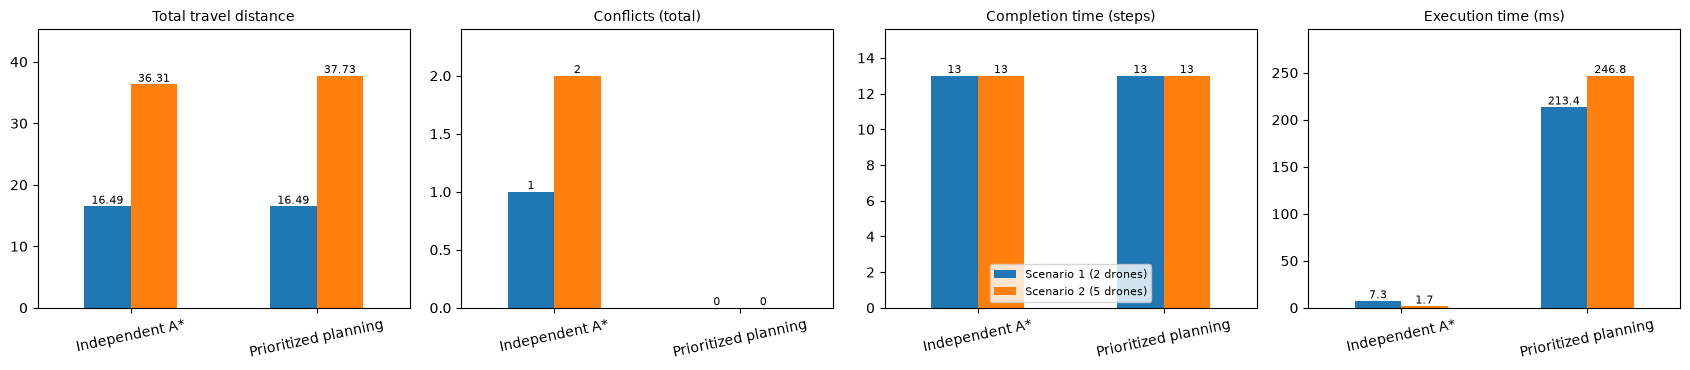

In [26]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, m in zip(ax, ["Total travel distance", "Conflicts (total)", "Completion time (steps)", "Execution time (ms)"]):
    metrics.loc[m].unstack(0).plot.bar(ax=a, rot=12, legend=(m == "Completion time (steps)"))
    a.set_title(m, fontsize=10); a.set_xlabel(""); a.margins(y=0.2)
    if a.get_legend(): a.legend(fontsize=8, loc="lower center")
    for cont in a.containers:
        a.bar_label(cont, fmt="%.4g", fontsize=8)
plt.tight_layout(); plt.show()

**Observations:**
- **Total travel distance:** bars are equal in Scenario 1 and only slightly higher with coordination in Scenario 2.
- **Conflicts:** independent A\* has 1 and 2 conflicts; prioritized planning has none.
- **Completion time:** all four bars are 13, so the mission time is unchanged.
- **Execution time:** coordination is slower by a large factor, but the time is still only tens of milliseconds.
- Overall, the only real cost of removing collisions is a little planning time (and a small detour in Scenario 2).

## 6.5 Visualisation of the Coordinated Movement


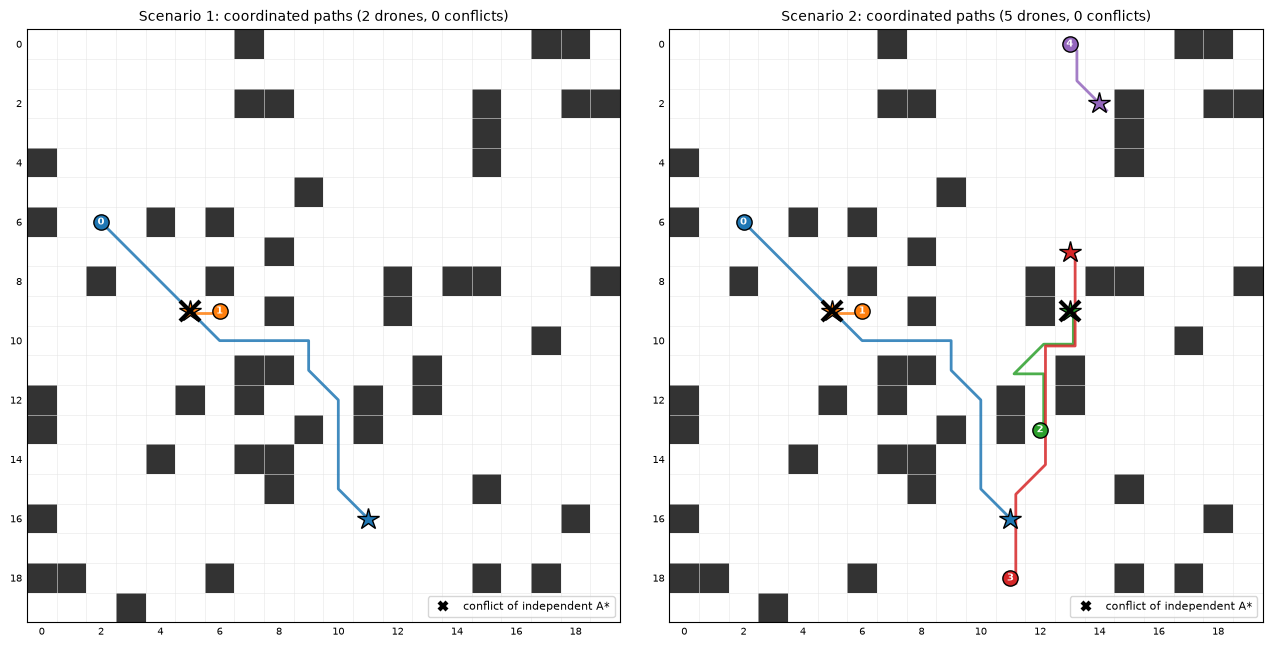

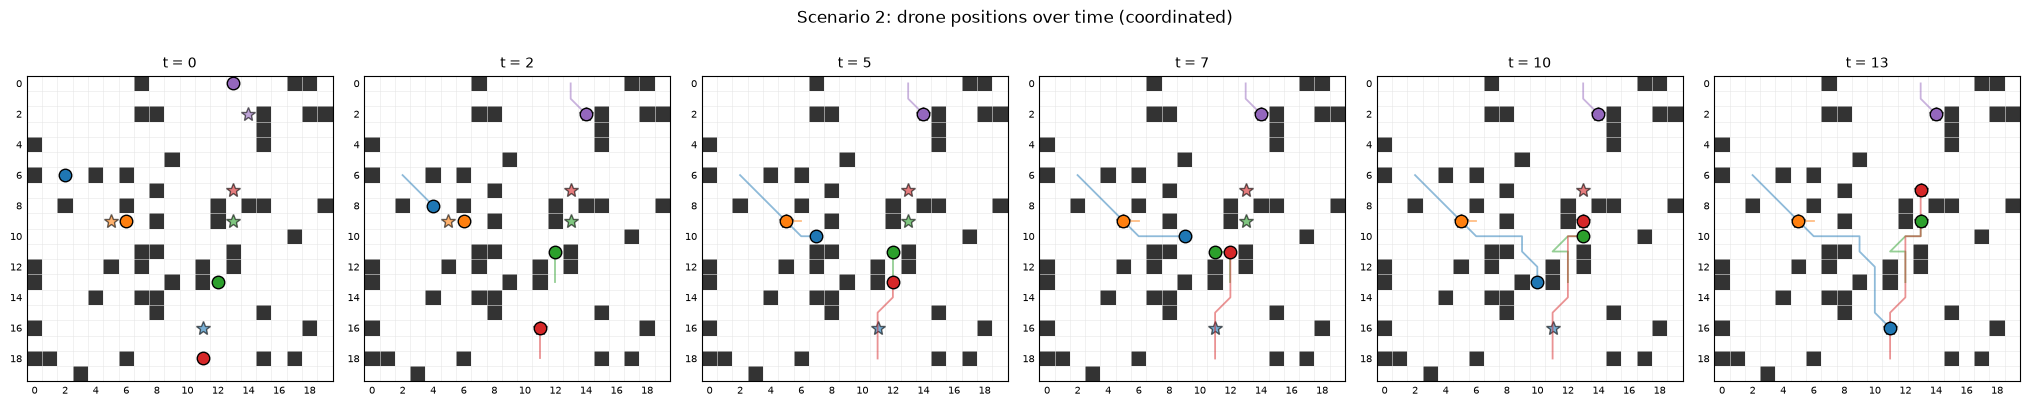

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6.3))
for a, n in zip(ax, (2, 5)):
    key = (f"Scenario {1 if n == 2 else 2} ({n} drones)", "Prioritized planning")
    draw_map(a, f"Scenario {1 if n == 2 else 2}: coordinated paths ({n} drones, "
                f"{results[key][1]['Conflicts (total)']} conflicts)")
    draw_drones(a, results[key][0])
    base = results[(key[0], "Independent A*")][0]
    for t in range(max(len(d.path) for d in base)):
        for i, j in itertools.combinations(range(len(base)), 2):
            if base[i].at(t) == base[j].at(t):
                a.plot(*base[i].at(t), "kx", ms=14, mew=3, zorder=9)
    a.plot([], [], "kx", mew=3, label="conflict of independent A*"); a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

drs = results[("Scenario 2 (5 drones)", "Prioritized planning")][0]
T = max(d.arrival_time for d in drs); times = sorted(set(np.linspace(0, T, 6).astype(int)))
fig, ax = plt.subplots(1, len(times), figsize=(3.4 * len(times), 3.9))
for a, t in zip(ax, times):
    draw_map(a, f"t = {t}")
    for d in drs:
        trail = [d.at(k) for k in range(t + 1)]
        a.plot([p[0] for p in trail], [p[1] for p in trail], "-", color=COLORS[d.id], lw=1.3, alpha=.5)
        a.plot(*d.goal, "*", color=COLORS[d.id], ms=10, mec="k", alpha=.6)
        a.plot(*d.at(t), "o", color=COLORS[d.id], ms=9, mec="k", zorder=5)
plt.suptitle("Scenario 2: drone positions over time (coordinated)", y=1.02); plt.tight_layout(); plt.show()

**Observations:**
- **Coordinated paths:** both scenarios end with 0 conflicts.
- In Scenario 1 the path of drone 0 is unchanged. Drone 1 stays at its start for 3 steps until drone 0 has passed the cell (5, 9), and then moves to its goal.
- In Scenario 2 drone 1 waits 3 steps and drone 2 waits 5 steps. Drone 2 also takes a short detour to the left of the corridor (around (11, 11)) so that drone 3 can pass first. This detour is the source of the extra 1.42 distance.
- **Snapshots:** the drones move at the same time. Drone 4 arrives early, drone 1 arrives at t = 4, and all drones are at their goals at t = 13, when drone 0 (blue) arrives last.
- The ordering is what prevents the conflicts: the drone that passes a goal cell does so before the owner of that goal arrives.

In [28]:
def wait_steps(d):
    # Count how many time steps a drone waited (stayed in the same cell)
    return sum(1 for a, b in zip(d.path, d.path[1:]) if a == b)

for n in (2, 5):
    sc = f"Scenario {1 if n == 2 else 2} ({n} drones)"
    ind, pri = metrics[(sc, "Independent A*")], metrics[(sc, "Prioritized planning")]
    waits = {d.id: wait_steps(d) for d in results[(sc, "Prioritized planning")][0] if wait_steps(d)}
    print(f"{sc}: conflicts {ind['Conflicts (total)']} -> {pri['Conflicts (total)']}, "
          f"distance {ind['Total travel distance']} -> {pri['Total travel distance']}, "
          f"completion time {ind['Completion time (steps)']} -> {pri['Completion time (steps)']} steps, "
          f"waiting steps per drone: {waits if waits else 'none'}")

Scenario 1 (2 drones): conflicts 1.0 -> 0.0, distance 16.49 -> 16.49, completion time 13.0 -> 13.0 steps, waiting steps per drone: {1: 3}
Scenario 2 (5 drones): conflicts 2.0 -> 0.0, distance 36.31 -> 37.73, completion time 13.0 -> 13.0 steps, waiting steps per drone: {1: 3, 2: 5}


**Observations:**
- Conflicts drop to 0 in both scenarios, and the completion time stays at 13 steps.
- Only drones 1 and 2 had to wait (3 and 5 steps), so the other drones were not affected.
- Waiting costs no distance. Scenario 1 therefore needs no extra distance, and Scenario 2 only a little because of the detour.

# 7. Test Cases

Eight tests check pathfinding, obstacle avoidance, conflict detection and coordination. A test passes if all its `assert` statements are true.

| Test | What it checks |
|---|---|
| `test_astar_empty_grid` | A\* uses 4 diagonal moves from corner to corner of an empty grid |
| `test_astar_avoids_obstacles_and_unreachable` | A\* goes around a wall and returns `None` if the goal is cut off |
| `test_no_corner_cutting` | a diagonal move between two obstacles is not allowed |
| `test_scenario_entries_are_valid` | all start and goal cells are free and inside the window |
| `test_conflict_detection` | vertex, swap and crossing conflicts are detected, and no false alarm |
| `test_head_on_drones_are_coordinated` | two drones flying towards each other collide without coordination and not with it |
| `test_waiting_in_a_corridor` | in a narrow corridor one drone steps into a side pocket |
| `test_coordinated_paths_are_valid` | real 5-drone experiment: correct start/goal, legal moves, 0 conflicts |

In [29]:
def small_grid(rows):
    # Building a small test map from text:@ = obstacle, . = free cell
    return Grid(np.array([[1 if ch == "@" else 0 for ch in r] for r in rows]))

def valid_path(g, path):
    # True if every step of the path is a legal move (wait, or a move to a neighbour cell)
    return all(a == b or any(n == b for n, _ in g.neighbors(a)) for a, b in zip(path, path[1:]))

def test_astar_empty_grid():
    g = small_grid(["....."] * 5); p = Planner(g).plan((0, 0), (4, 4))
    assert len(p) == 5 and abs(sum(Grid.step_cost(a, b) for a, b in zip(p, p[1:])) - 4 * SQRT2) < 1e-9

def test_astar_avoids_obstacles_and_unreachable():
    g = small_grid(["..@..", "..@..", "..@..", ".....", "....."]); p = Planner(g).plan((0, 0), (4, 0))
    assert all(g.free(c) for c in p) and valid_path(g, p) and len(p) - 1 > 4
    assert Planner(small_grid([".@."])).plan((0, 0), (2, 0)) is None

def test_no_corner_cutting():
    g = small_grid([".@", "@."]); assert list(g.neighbors((0, 0))) == []
def test_scenario_entries_are_valid():
    for r in agents5.itertuples():
        assert env.free((r.sx, r.sy)) and env.free((r.gx, r.gy)) and max(r.sx, r.sy, r.gx, r.gy) < N

def test_conflict_detection():
    assert find_conflicts({0: [(0, 0), (1, 0), (2, 0)], 1: [(2, 0), (1, 0), (0, 0)]})["vertex"] == 1
    assert find_conflicts({0: [(0, 0), (1, 0)], 1: [(1, 0), (0, 0)]})["swap"] == 1
    assert find_conflicts({0: [(0, 0), (1, 1)], 1: [(1, 0), (0, 1)]})["crossing"] == 1
    assert sum(find_conflicts({0: [(0, 0), (1, 0)], 1: [(0, 2), (1, 2)]}).values()) == 0

def test_head_on_drones_are_coordinated():
    g = small_grid(["......."] * 3); d = [Drone(0, (0, 1), (6, 1)), Drone(1, (6, 1), (0, 1))]
    Coordinator(g).plan_independent(d); assert sum(find_conflicts({x.id: x.path for x in d}).values()) > 0
    Coordinator(g).plan_prioritized(d)
    assert sum(find_conflicts({x.id: x.path for x in d}).values()) == 0 and all(x.reached for x in d)

def test_waiting_in_a_corridor():
    g = small_grid(["@@.@@", ".....", "@@@@@"]); d = [Drone(0, (0, 1), (4, 1)), Drone(1, (3, 1), (1, 1))]
    Coordinator(g).plan_independent(d); assert find_conflicts({x.id: x.path for x in d})["swap"] > 0
    Coordinator(g).plan_prioritized(d)
    assert sum(find_conflicts({x.id: x.path for x in d}).values()) == 0 and all(x.reached for x in d)

def test_coordinated_paths_are_valid():
    for d in results[("Scenario 2 (5 drones)", "Prioritized planning")][0]:
        assert d.path[0] == d.start and d.path[-1] == d.goal and valid_path(env, d.path)
    assert metrics[("Scenario 2 (5 drones)", "Prioritized planning")]["Conflicts (total)"] == 0

tests = [v for k, v in sorted(globals().items()) if k.startswith("test_") and callable(v)]
for t in tests:
    try:
        t(); print("PASS ", t.__name__)
    except AssertionError as e:
        print("FAIL ", t.__name__, e)

PASS  test_astar_avoids_obstacles_and_unreachable
PASS  test_astar_empty_grid
PASS  test_conflict_detection
PASS  test_coordinated_paths_are_valid
PASS  test_head_on_drones_are_coordinated
PASS  test_no_corner_cutting
PASS  test_scenario_entries_are_valid
PASS  test_waiting_in_a_corridor


**Observations:**
- All 8 tests print **PASS**.
- Independent A\* really collides in the two constructed situations (head-on and corridor), and prioritized planning resolves both.
- The real 5-drone experiment is also verified: every path starts at the start, ends at the goal, uses only legal moves and has no conflict.

# 8. Quantum Computing Extension

## 8.1 Which Part of the Problem Could Benefit?
A path for **one** drone is easy (A\*). The hard part is the **joint decision**: which combination of paths and waiting times of all drones has no conflict and the lowest cost? With `k` candidate paths per drone and `n` drones there are `kⁿ` combinations. Problems of this type can be written as a **QUBO**, which quantum annealers and QAOA accept.

## 8.2 QUBO Representation
A QUBO minimises `E(x) = xᵀQx` for a binary vector `x`. Here `x(i,p) = 1` means that drone **i** uses candidate path **p**.

| Requirement | Term in the energy |
|---|---|
| short, quick paths | `Σ cost(i,p) · x(i,p)` (cost = distance + 0.05 · arrival time) |
| exactly one path per drone | `P · Σᵢ ( Σₚ x(i,p) − 1 )²` |
| no collision between two chosen paths | `W · c(i,p,j,q) · x(i,p) · x(j,q)`, with `c` = number of conflicts of the two paths |

A violated rule costs a large penalty (`P`, `W`), so the lowest-energy state is a valid, conflict-free plan.

## 8.3 Small Quantum-Inspired Example
For each of the 5 drones, candidate paths are built from up to 3 routes combined with waiting 0, 6 or 12 steps at the start. The QUBO is solved with **simulated annealing** (a classical, quantum-inspired method) and compared with the exact optimum found by trying all combinations.

In [30]:
planner = Planner(env)
TIME_W, P_ONE, W_CONF = 0.05, 100.0, 50.0

def candidate_paths(d, delays=(0, 6, 12)):
    base = planner.plan(d.start, d.goal); routes = [base]
    for k in (len(base) // 3, 2 * len(base) // 3):
        if 0 < k < len(base) - 1:
            blocked = Grid(env.grid.copy()); blocked.grid[base[k][1], base[k][0]] = 1
            alt = Planner(blocked).plan(d.start, d.goal)
            if alt and alt not in routes:
                routes.append(alt)
    return [[d.start] * w + r for r in routes for w in delays]

def path_cost(p):
    return sum(Grid.step_cost(a, b) for a, b in zip(p, p[1:])) + TIME_W * (len(p) - 1)

cands = {d.id: candidate_paths(d) for d in drones5}
var = [(i, k) for i in cands for k in range(len(cands[i]))]
n_var = len(var)

Q, offset = np.zeros((n_var, n_var)), 0.0
for a, (i, p) in enumerate(var):
    Q[a, a] += path_cost(cands[i][p]) - P_ONE
    for b, (j, q) in enumerate(var):
        if b <= a:
            continue
        if i == j:
            Q[a, b] += 2 * P_ONE
        else:
            Q[a, b] += W_CONF * sum(find_conflicts({0: cands[i][p], 1: cands[j][q]}).values())
offset = P_ONE * len(cands)
print(f"{len(cands)} drones, {[len(v) for v in cands.values()]} candidate paths -> {n_var} binary variables, "
      f"{int(np.count_nonzero(Q))} non-zero QUBO coefficients")

5 drones, [9, 3, 9, 6, 6] candidate paths -> 33 binary variables, 201 non-zero QUBO coefficients


**Observations:**
- The 5 drones have 9, 3, 9, 6 and 6 candidate paths, which gives **33 binary variables**.
- The QUBO matrix has 201 non-zero coefficients. They come from the cost terms, the "one path per drone" penalty and the conflict penalties between paths of different drones.
- Drone 1 has only 3 candidates because its trip is a single step, so no detour route exists.

In [31]:
energy = lambda x: float(x @ Q @ x + offset)

def decode(x):
    # QUBO solution -> (plan, valid). valid = exactly one path per drone.
    pick = {i: [k for (ii, k), v in zip(var, x) if ii == i and v > .5] for i in cands}
    return {i: cands[i][ks[0]] for i, ks in pick.items() if len(ks) == 1}, all(len(ks) == 1 for ks in pick.values())

def plan_summary(plan):
    # small table of numbers for one complete plan
    return {"Total travel distance": round(sum(Grid.step_cost(a, b) for p in plan.values() for a, b in zip(p, p[1:])), 2),
            "Conflicts": sum(find_conflicts(plan).values()), "Completion time (steps)": max(len(p) - 1 for p in plan.values()),
            "QUBO objective": round(sum(path_cost(p) for p in plan.values()), 3)}

t0 = time.perf_counter(); best_e, best_x = math.inf, None

for combo in itertools.product(*[range(len(cands[i])) for i in cands]):
    x = np.zeros(n_var)
    for i, k in zip(cands, combo):
        x[var.index((i, k))] = 1
    e = energy(x)
    if e < best_e:
        best_e, best_x = e, x
exact_time = time.perf_counter() - t0

def simulated_annealing(steps=80000, t0=30.0, t1=0.05, seed=0):
    # t0 = starting temperature (hot), t1 = final temperature (cold), seed makes the result repeatable
    rng = np.random.default_rng(seed); S = (Q + Q.T) / 2; np.fill_diagonal(S, np.diag(Q))
    x = rng.integers(0, 2, n_var).astype(float); e = energy(x); bx, be = x.copy(), e
    for s in range(steps):
        T, k = t0 * (t1 / t0) ** (s / steps), rng.integers(n_var)
        delta = (1 - 2 * x[k]) * (2 * (S[k] @ x) - 2 * S[k, k] * x[k] + S[k, k])
        if delta <= 0 or rng.random() < math.exp(-delta / T):
            x[k] = 1 - x[k]; e += delta
            if e < be - 1e-9:
                bx, be = x.copy(), e
    return bx, be

t0 = time.perf_counter(); runs = [simulated_annealing(seed=s) for s in range(20)]; sa_time = (time.perf_counter() - t0) / 20
sa_x, sa_e = min(runs, key=lambda r: r[1])

def good(x):
    plan, valid = decode(x); return valid and sum(find_conflicts(plan).values()) == 0
hits = sum(abs(e - best_e) < 1e-6 for _, e in runs); feasible = sum(good(x) for x, _ in runs)
print(f"Exact minimum energy: {best_e:.3f} ({exact_time:.1f} s)  |  best SA energy: {sa_e:.3f}  (gap {100 * (sa_e - best_e) / best_e:.2f} %)")
print(f"SA: {feasible}/20 runs gave a valid conflict-free plan, {hits}/20 hit the exact optimum, "
      f"mean energy {np.mean([e for _, e in runs]):.3f}  ({1000 * sa_time:.0f} ms per run)")

Exact minimum energy: 38.756 (0.4 s)  |  best SA energy: 39.056  (gap 0.77 %)
SA: 20/20 runs gave a valid conflict-free plan, 0/20 hit the exact optimum, mean energy 39.961  (1544 ms per run)


**Observations:**
- The exact optimum (all 9·3·9·6·6 = 8,748 combinations) has energy 38.756 and takes a fraction of a second.
- The best simulated annealing result has energy 39.056, only **0.77 %** above the exact optimum.
- All 20 annealing runs returned a valid plan with one path per drone and **no conflicts**.
- None of the 20 runs hit the exact optimum exactly (mean energy 39.961). Annealing is a heuristic and gives no guarantee of the best answer.
- One annealing run takes longer than the brute-force search here, so there is **no speed advantage** at this size.

,Total travel distance,Conflicts,Completion time (steps),QUBO objective
Independent A* (shortest paths),36.31,2.0,13.0,37.964
Prioritized planning (classical),37.73,0.0,13.0,39.828
QUBO exact optimum (brute force),36.56,0.0,13.0,38.756
QUBO + simulated annealing,36.56,0.0,13.0,39.056


SA solution valid (one path per drone): True


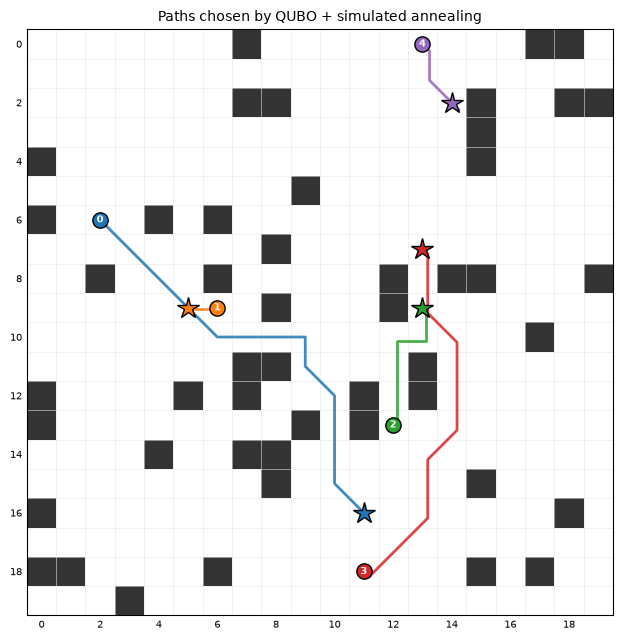

In [32]:
plans = {"Independent A* (shortest paths)": {d.id: d.path for d in results[("Scenario 2 (5 drones)", "Independent A*")][0]},
         "Prioritized planning (classical)": {d.id: d.path for d in results[("Scenario 2 (5 drones)", "Prioritized planning")][0]},
         "QUBO exact optimum (brute force)": decode(best_x)[0],
         "QUBO + simulated annealing": decode(sa_x)[0]}
display(pd.DataFrame({k: plan_summary(v) for k, v in plans.items()}).T)
print("SA solution valid (one path per drone):", decode(sa_x)[1])

fig, ax = plt.subplots(figsize=(6.5, 6.5)); draw_map(ax, "Paths chosen by QUBO + simulated annealing")
sa_drones = [Drone(i, d.start, d.goal) for i, d in enumerate(drones5)]
for d in sa_drones:
    d.path = decode(sa_x)[0][d.id]
draw_drones(ax, sa_drones); plt.tight_layout(); plt.show()

**Observations:**

| Method | Distance | Conflicts | Completion time |
|---|---|---|---|
| Independent A\* | 36.31 (shortest) | 2 | 13 |
| Prioritized planning | 37.73 | 0 | 13 |
| QUBO exact optimum | 36.56 | 0 | 13 |
| QUBO + simulated annealing | 36.56 | 0 | 13 |

- Both QUBO methods are conflict-free and need less distance than prioritized planning (36.56 against 37.73), because they choose all paths together.
- Independent A\* is shortest only because it ignores the other drones; it has 2 conflicts.
- The SA plan reaches the same distance as the exact optimum; its objective is slightly higher (39.056 against 38.756) because of a small difference in waiting time.
- In the plot, drone 3 takes a longer route to the east so that it does not meet drone 2 in the corridor.
- The QUBO choice is limited to the candidate paths it is given, so it is a proof of concept, not a replacement for prioritized planning.

## 8.4 Advantages and Limitations

| | Quantum-assisted (QUBO) | Classical (A\* + prioritized planning) |
|---|---|---|
| **Advantages** | considers all drones together; extra rules (no-fly zones, battery) are just more penalty terms; the same QUBO can go to a quantum annealer, QAOA or a classical solver | fast, simple, works on the full map, easy to explain |
| **Limitations** | variables = drones × candidate paths (thousands for big maps); penalty weights `P`, `W` need tuning; candidates must be created first by a classical method; no optimality guarantee; current quantum hardware is small and noisy; **no speed-up is claimed** | greedy: a drone planned early never gives way to improve the total; depends on the priority order; can fail although a solution exists |

# 9.Limitations, Improvements and Summary


## 9.1 Limitations
- Prioritized planning is a **heuristic**; a bad priority order can make a drone fail. Only "longest trip first" was used.
- Drones park at their goal and block that cell. The world is ideal: no wind, no delays, no drone size, no communication errors.
- Only 2 and 5 drones were tested, on one 20 × 20 window of one map, with one scenario file.
- The QUBO example is small and was not run on a quantum computer.

## 9.2 Possible Improvements
- Use **Conflict-Based Search (CBS)**, try several priority orders, or re-plan during the flight.
- Test the full 32 × 32 map, more drones, 3D movement and battery limits.
- Build larger QUBOs with tuned penalty weights and test them on a quantum annealer or a QAOA simulator.

## 9.3 Summary

**What I did**
- Read the Moving AI map and even scenario files and used a 20 × 20 window.
- Built an object-oriented system (`Grid`, `Drone`, `Planner`, `Reservations`, `Coordinator`).
- Compared independent A\* with prioritized planning for 2 and 5 drones on five metrics.
- Verified the code with 8 test cases.
- Formulated route selection as a QUBO and solved it with simulated annealing.

**Final result**
- Independent A\*: 1 and 2 conflicts. Prioritized planning: **0 conflicts**, 100 % of drones reaching their goals, same completion time (13 steps).
- Cost of coordination: a few waiting steps, up to +1.42 distance (Scenario 2) and tens of milliseconds more planning time.
- Simulated annealing on the QUBO: conflict-free plans within 0.77 % of the exact optimum.

**Conclusion:** coordination with a reservation table makes the drones safe at a very small cost. The QUBO shows how multi-agent coordination can be moved to a quantum-ready form; no quantum speed-up is claimed.